<a href="https://colab.research.google.com/github/salvin2000/Deep-Learning-projects/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Architecture of CNN
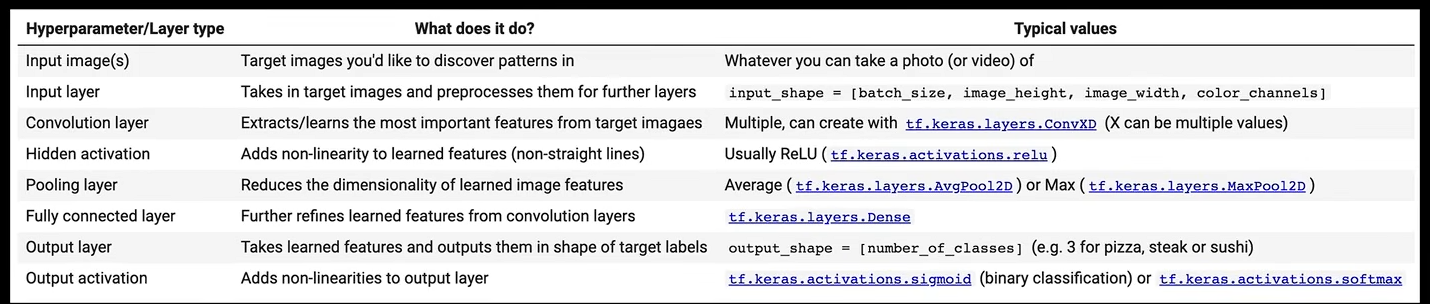

In [ ]:
# introduction to convolutional neural networks and computer vision with tensorflow

# introduction to convolutional neural networks and computer vision with tensorflow

computer vision is the practice of writing algorithms which can discover patterns in visual data. SUch as the camera if a self-driving car recognizong the car in front.

Here's the text from the image:

---

## Get the data

The images we're working with are from the Food101 dataset (101 different classes of food): https://www.kaggle.com/dansbecker/food-101

However we've modified it to only use two classes (pizza 🍕 & steak 🥩) using the image data modification notebook:
https://github.com/mrdbourke/tensorflow-deep-learning/blob/main/extras/image_data_modification.ipynb

Note: we start witha smaller dataset so we can experiment quickly and figure what works (or better yet what doesn't work)
before scalling up



In [ ]:
# get the data
import zipfile

!wget https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip

# unzip the downloaded file

zip_ref = zipfile.ZipFile("pizza_steak.zip")
zip_ref.extractall()
zip_ref.close()



--2026-07-06 15:04:23--  https://storage.googleapis.com/ztm_tf_course/food_vision/pizza_steak.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 74.125.137.207, 142.250.101.207, 142.250.141.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|74.125.137.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 109540975 (104M) [application/zip]
Saving to: ‘pizza_steak.zip’

pizza_steak.zip     100%[===================>] 104.47M   107MB/s    in 1.0s    

2026-07-06 15:04:24 (107 MB/s) - ‘pizza_steak.zip’ saved [109540975/109540975]



 inspect the data( become one with it)

a very crucial step at the beginning of any machine learning project is becoming one with the data.

and for a computer vision project ..... this usually means visualinzing  many sample of your data





os.walk()|path, dirs, files|Walk all folders recursively

os.listdir()|list|List contents of one folder

os.path.join()|string|Build file paths safely

os.path.exists()|True/False|Check if path exists

os.path.isfile()|True/False|Check if it's a file

os.path.isdir()|True/False|Check if it's a folder

os.getcwd()|string|Get current folder

os.makedirs()|nothing|Create folders

os.rename()|nothing|Rename file/folder

os.remove()|nothing|Delete a file

os.path.getsize()|integer|Get file size in bytes

In [ ]:
!ls pizza_steak # ls stands for list. it basically list the file in the pizza stake


test  train


In [ ]:
!ls pizza_steak/train/

pizza  steak


In [ ]:
!ls pizza_steak/train/steak

1000205.jpg  1647351.jpg  2238681.jpg  2824680.jpg  3375959.jpg  417368.jpg
100135.jpg   1650002.jpg  2238802.jpg  2825100.jpg  3381560.jpg  4176.jpg
101312.jpg   165639.jpg   2254705.jpg  2826987.jpg  3382936.jpg  42125.jpg
1021458.jpg  1658186.jpg  225990.jpg   2832499.jpg  3386119.jpg  421476.jpg
1032846.jpg  1658443.jpg  2260231.jpg  2832960.jpg  3388717.jpg  421561.jpg
10380.jpg    165964.jpg   2268692.jpg  285045.jpg   3389138.jpg  438871.jpg
1049459.jpg  167069.jpg   2271133.jpg  285147.jpg   3393547.jpg  43924.jpg
1053665.jpg  1675632.jpg  227576.jpg   2855315.jpg  3393688.jpg  440188.jpg
1068516.jpg  1678108.jpg  2283057.jpg  2856066.jpg  3396589.jpg  442757.jpg
1068975.jpg  168006.jpg   2286639.jpg  2859933.jpg  339891.jpg	 443210.jpg
1081258.jpg  1682496.jpg  2287136.jpg  286219.jpg   3417789.jpg  444064.jpg
1090122.jpg  1684438.jpg  2291292.jpg  2862562.jpg  3425047.jpg  444709.jpg
1093966.jpg  168775.jpg   229323.jpg   2865730.jpg  3434983.jpg  447557.jpg
1098844.jpg  1697

In [ ]:
import os

# walk through the pizza_steak directory and list number of files

for dirpath, dirnames, filenames in os.walk("pizza_steak"):
  print(f"there are {len(dirnames)} directories and {len(filenames)} images in' {dirpath}'.")

there are 2 directories and 0 images in' pizza_steak'.
there are 2 directories and 0 images in' pizza_steak/train'.
there are 0 directories and 750 images in' pizza_steak/train/steak'.
there are 0 directories and 750 images in' pizza_steak/train/pizza'.
there are 2 directories and 0 images in' pizza_steak/test'.
there are 0 directories and 250 images in' pizza_steak/test/steak'.
there are 0 directories and 250 images in' pizza_steak/test/pizza'.


In [ ]:
!ls  -la pizza_steak


total 16
drwxr-xr-x 4 root root 4096 Jul  6 15:04 .
drwxr-xr-x 1 root root 4096 Jul  6 15:04 ..
drwxr-xr-x 4 root root 4096 Jul  6 15:04 test
drwxr-xr-x 4 root root 4096 Jul  6 15:04 train


In [ ]:
# another way to find out how many images are in a file

num_steak_images_train = len(os.listdir("pizza_steak/train/steak"))

num_steak_images_train

750

to visualize out images, first let's get the class names programmatically

In [ ]:
# get the classnames programmatically.

import pathlib
import numpy as np
data_dir = pathlib.Path("pizza_steak/train")
class_names = np.array(sorted([item.name for item in data_dir.glob("*")])) # created a list of class_names from the subdirectories
class_names = class_names[:] # to remove .DS store
print(class_names)


#[item.name for item in data_dir.glob("*")] means:
#“For each item in the train directory, take its .name and put all those names into a list.”



['pizza' 'steak']


In [ ]:
# let's visualize our images
import matplotlib.pyplot as plt # to view images
import matplotlib.image as mpimg
import random

def view_random_image(target_dir, target_class):
  # setup the target directory (we'll view images from here)
  target_folder = target_dir+target_class

  # get a random image path
  random_image  = random.sample(os.listdir(target_folder),1)
  print(random_image)

  #read in the image and plot it using matplotlib
  img = mpimg.imread(target_folder + "/" + random_image[0] )
  plt.imshow(img)
  plt.title(target_class)
  plt.axis("off");

  print(f"image shape: {img.shape}") # show the shape of the image

  return img



(512, 512, 3) is the shape of an image stored as a NumPy array:

512 → number of rows (image height in pixels).

512 → number of columns (image width in pixels).

3 → number of color channels, typically RGB (Red, Green, Blue).

So:

The image is 512 pixels tall × 512 pixels wide, and

Each pixel is represented by 3 numbers (R, G, B values), usually in the range 0–255 or 0.0–1.0.

In short:
(512, 512, 3) means a square RGB image of size 512×512 pixels.


array([[[181, 119, 144],
        [176, 114, 139],
        [170, 106, 132],
        ...,
        [134, 114, 151],
        [137, 117, 154],
        [149, 129, 166]],

       [[179, 117, 142],
        [175, 113, 138],
        [170, 106, 132],
        ...,
        [142, 122, 159],
        [144, 124, 161],
        [153, 133, 170]],

       [[176, 112, 138],
        [173, 109, 135],
        [170, 104, 131],
        ...,
        [138, 120, 158],
        [142, 124, 162],
        [148, 130, 168]],

       ...,

       [[173, 135, 148],
        [171, 133, 146],
        [167, 129, 140],
        ...,
        [215, 194, 209],
        [217, 196, 211],
        [215, 194, 209]],

       [[176, 136, 147],
        [174, 134, 145],
        [171, 131, 142],
        ...,
        [215, 194, 209],
        [217, 196, 211],
        [215, 194, 209]],

       [[176, 136, 147],
        [175, 135, 146],
        [172, 132, 143],
        ...,
        [217, 196, 211],
        [219, 198, 213],
        [218, 197, 212]]], dtype=uint8)
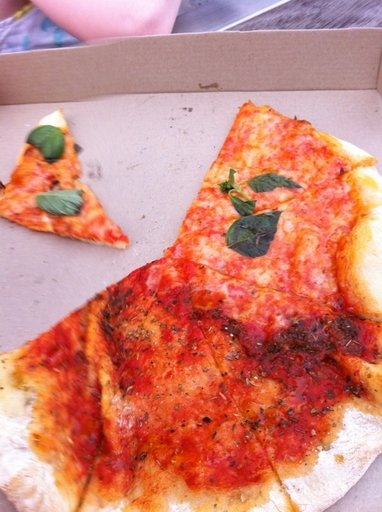

In [ ]:
img



['218711.jpg']
image shape: (512, 382, 3)


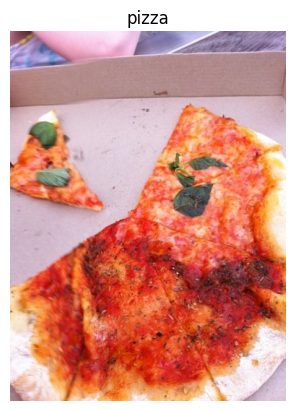

In [ ]:
# view a random image from the training dataset
img = view_random_image (target_dir="pizza_steak/train/",
                         target_class="pizza")

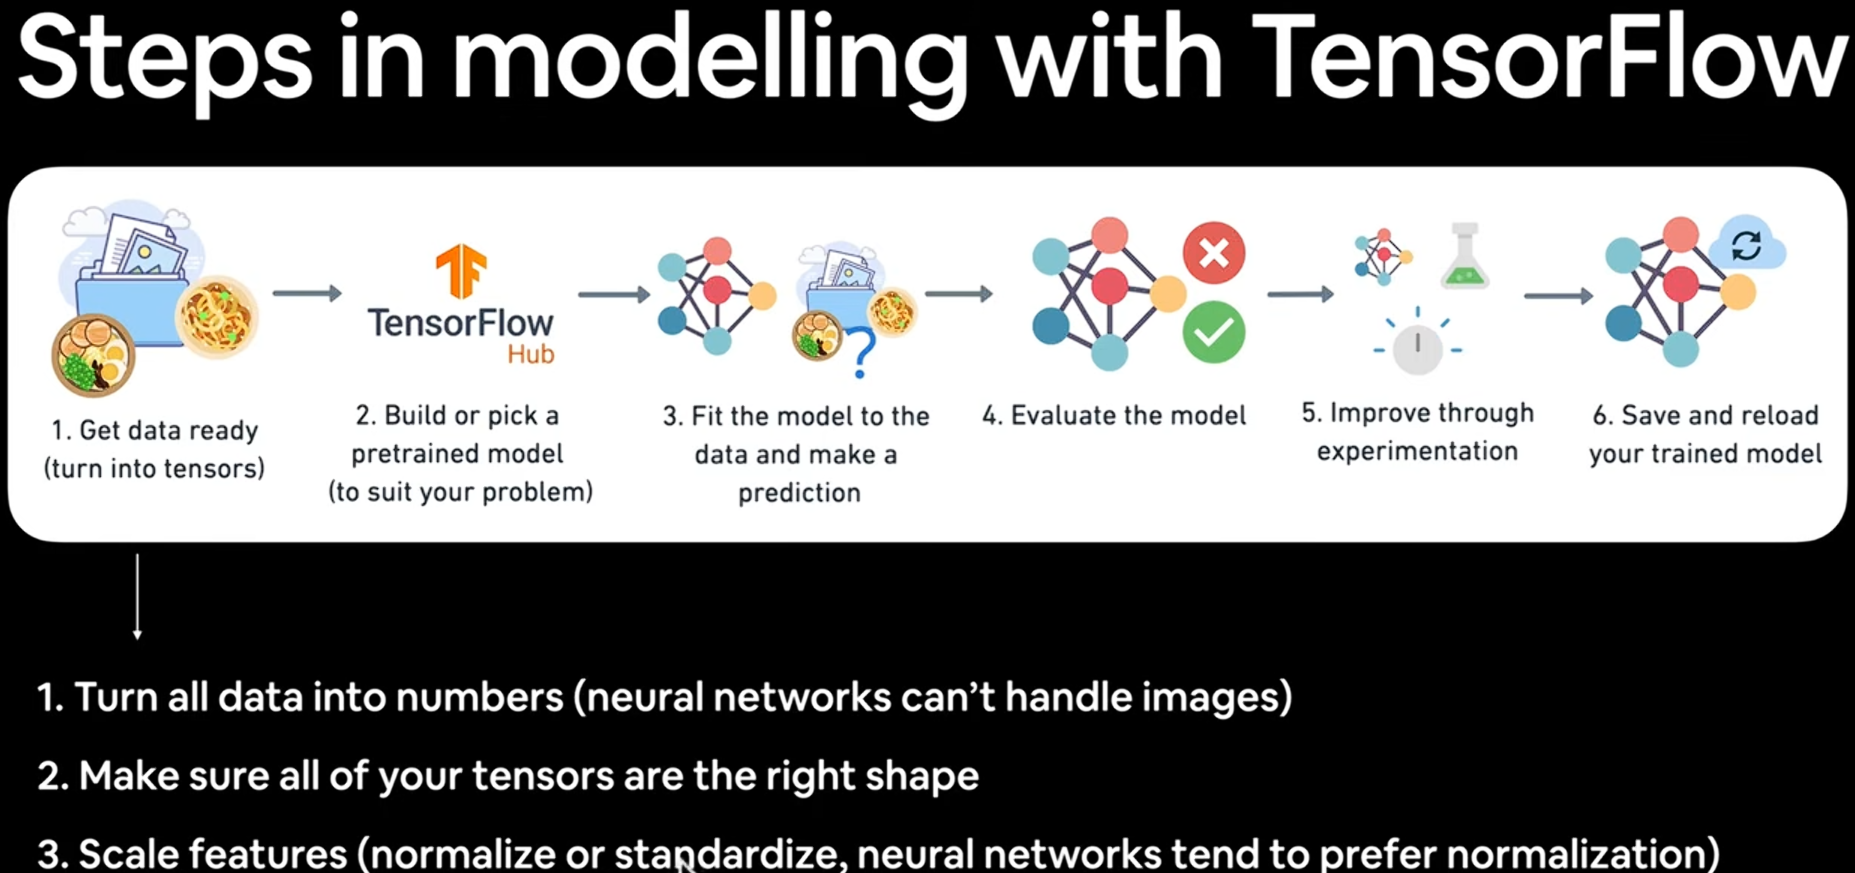

In [ ]:
# the images we've imported and plotted are actually giant arrays/tensors of different pixel values

import tensorflow as tf
tf.constant(img)



<tf.Tensor: shape=(512, 382, 3), dtype=uint8, numpy=
array([[[181, 119, 144],
        [176, 114, 139],
        [170, 106, 132],
        ...,
        [134, 114, 151],
        [137, 117, 154],
        [149, 129, 166]],

       [[179, 117, 142],
        [175, 113, 138],
        [170, 106, 132],
        ...,
        [142, 122, 159],
        [144, 124, 161],
        [153, 133, 170]],

       [[176, 112, 138],
        [173, 109, 135],
        [170, 104, 131],
        ...,
        [138, 120, 158],
        [142, 124, 162],
        [148, 130, 168]],

       ...,

       [[173, 135, 148],
        [171, 133, 146],
        [167, 129, 140],
        ...,
        [215, 194, 209],
        [217, 196, 211],
        [215, 194, 209]],

       [[176, 136, 147],
        [174, 134, 145],
        [171, 131, 142],
        ...,
        [215, 194, 209],
        [217, 196, 211],
        [215, 194, 209]],

       [[176, 136, 147],
        [175, 135, 146],
        [172, 132, 143],
        ...,
        [217, 196, 21

In [ ]:
# view the image shape
img.shape # return width, height , colour channels

(512, 382, 3)

Note: as we've discussed before, many machine learning models, including neural networks prefer the values they work with to be between 0 and 1. knowing this, one of the most common preprocessing steps for working with images is to scale (also referred to as normalize) their pixel values by dividing the image arrays by 255. (since the maximum pixel value

In [ ]:
# get all the pixel values between 0 & 1
img/225

array([[[0.80444444, 0.52888889, 0.64      ],
        [0.78222222, 0.50666667, 0.61777778],
        [0.75555556, 0.47111111, 0.58666667],
        ...,
        [0.59555556, 0.50666667, 0.67111111],
        [0.60888889, 0.52      , 0.68444444],
        [0.66222222, 0.57333333, 0.73777778]],

       [[0.79555556, 0.52      , 0.63111111],
        [0.77777778, 0.50222222, 0.61333333],
        [0.75555556, 0.47111111, 0.58666667],
        ...,
        [0.63111111, 0.54222222, 0.70666667],
        [0.64      , 0.55111111, 0.71555556],
        [0.68      , 0.59111111, 0.75555556]],

       [[0.78222222, 0.49777778, 0.61333333],
        [0.76888889, 0.48444444, 0.6       ],
        [0.75555556, 0.46222222, 0.58222222],
        ...,
        [0.61333333, 0.53333333, 0.70222222],
        [0.63111111, 0.55111111, 0.72      ],
        [0.65777778, 0.57777778, 0.74666667]],

       ...,

       [[0.76888889, 0.6       , 0.65777778],
        [0.76      , 0.59111111, 0.64888889],
        [0.74222222, 0

# an end-to-end example

let's build a convolutional neural network to find patterns in our images, more specifically we need a way to

* load our images
* preprocess our images
* build a CNN to find patterns in our images
* compile our CNN
* fit the CNN to our training data


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# set the seed
tf.random.set_seed(42)

# preprocess data (get all of the pixel values between 0 & 1, also called scaling and normalization)
train_datagen = ImageDataGenerator(rescale=1./255)
valid_datagen = ImageDataGenerator(rescale=1./255)

# setup paths to our directories
train_dir = "/content/pizza_steak/train"
test_dir = "pizza_steak/test"


# import data from directories and turn it into batches
train_data = train_datagen.flow_from_directory(directory=train_dir,
                                               batch_size=32,
                                               target_size=(224,224),
                                               class_mode="binary",
                                               seed=42)

valid_data =valid_datagen.flow_from_directory(directory=test_dir,
                                              batch_size=32,
                                              target_size=(224,224),
                                              class_mode="binary",
                                              seed=42)


# build a CNN model (same as the tiny VGG in the CNN explainer website)
model_1 = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(filters=10,
                           kernel_size=3,
                           activation="relu",
                           input_shape=(224,224,3)),
    tf.keras.layers.Conv2D(10,3,activation="relu"),
    tf.keras.layers.MaxPool2D(pool_size=2,
                              padding="valid"),
    tf.keras.layers.Conv2D(10,3,activation="relu"),
    tf.keras.layers.Conv2D(10,3,activation="relu"),
    tf.keras.layers.MaxPool2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1,activation="sigmoid")
])

# compile our CNN
model_1.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

# fit the model
history_1 = model_1.fit(train_data,
                        epochs=5,
                        steps_per_epoch=len(train_data),
                        validation_data=valid_data,
                        validation_steps=len(valid_data))

Found 1500 images belonging to 2 classes.
Found 500 images belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 235ms/step - accuracy: 0.6547 - loss: 0.6117 - val_accuracy: 0.8360 - val_loss: 0.4104
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.7947 - loss: 0.4670 - val_accuracy: 0.8460 - val_loss: 0.3551
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.8180 - loss: 0.4086 - val_accuracy: 0.8600 - val_loss: 0.3293
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 131ms/step - accuracy: 0.8333 - loss: 0.3728 - val_accuracy: 0.8780 - val_loss: 0.3228
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 119ms/step - accuracy: 0.8633 - loss: 0.3296 - val_accuracy: 0.8380 - val_loss: 0.3810


In [ ]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 10)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28090)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        28,091 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,305 (364.48 KB)

 Trainable params: 31,101 (121.49 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 62,204 (242.99 KB)

Now, you might be wondering where that came from, but if we go 1500 / 32 because we've got a batch size of 32, what does that equal? 46.875.
16:24:2516 hours, 24 minutes, 25 secondsSo, now we have 47 batches of 32 images and their labels because there's 1500
16:24:3316 hours, 24 minutes, 33 secondstotal images. Now, the reason we put things into batches is because that way it can all fit in memory of our computer
16:24:4216 hours, 24 minutes, 42 secondschip. So if we tried to calculate uh the patterns on all images in one hit, our computer might run out of memory. But if
16:24:4916 hours, 24 minutes, 49 secondswe merge them or if we splice them into batches, it gives our computer a chance to calculate the patterns on the first
16:24:5616 hours, 24 minutes, 56 seconds32 images, then the second 32, the third 32, and so on and so on to work out the patterns for the overall entire image

** practice/exercise:** go through the CNN explainer website for of 10 minutes and compare our neural networks with theirs https://poloclub.github.io/cnn-explainer/

## using the same model as before

let's replicate the model we've built in a previous section to see it it works with our image data.

the model we've building is from the [tensorflow playground](https://playground.tensorflow.org/#activation=relu&batchSize=18&dataset=circle&regDataset=reg-plane&learningRate=0.001&regularizationRate=0&noise=10&networkShape=7,6,5,3,3,2&seed=0.26794&showTestData=true&discretize=false&percTrainData=80&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false)


In [ ]:
# set random seed
tf.random.set_seed(42)

# create a model to replicate the tensorflow playground model
model_2= tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(224,224,3)), # Flatten the input images
    tf.keras.layers.Dense(10,activation="relu"), # Added units argument
    tf.keras.layers.Dense(10,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid")
])

model_2.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

# fit the model

history_2 = model_2.fit(train_data,
                        epochs=5,
                        steps_per_epoch=len(train_data),
                        validation_data=valid_data,
                        validation_steps=len(valid_data))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 9s 153ms/step - accuracy: 0.6487 - loss: 5.5100 - val_accuracy: 0.7160 - val_loss: 0.8447
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.7187 - loss: 0.6455 - val_accuracy: 0.7260 - val_loss: 0.5243
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 129ms/step - accuracy: 0.7820 - loss: 0.4925 - val_accuracy: 0.7200 - val_loss: 0.5226
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.7687 - loss: 0.4919 - val_accuracy: 0.7740 - val_loss: 0.4707
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - accuracy: 0.8207 - loss: 0.4326 - val_accuracy: 0.8020 - val_loss: 0.4562


In [ ]:
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │     1,505,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,516,235 (17.23 MB)

 Trainable params: 1,505,411 (5.74 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,010,824 (11.49 MB)

despite having 20x more parameters than our cnn (model_1), model_2 performs terribly... let's to improve it.

In [ ]:
#

tf.random.set_seed(42)

# create the model (same as above)
model_3= tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(224,224,3)),
    tf.keras.layers.Dense(100, activation="relu"), # Flatten the input images
    tf.keras.layers.Dense(100,activation="relu"), # Added units argument
    tf.keras.layers.Dense(100,activation="relu"),
    tf.keras.layers.Dense(1,activation="sigmoid")
])

# compile the model
model_3.compile(loss="binary_crossentropy",
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])

# fit the model
history_3 = model_3.fit(train_data,
                        epochs=5,
                        steps_per_epoch=len(train_data),
                        validation_data=valid_data,
                        validation_steps=len(valid_data))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 158ms/step - accuracy: 0.6287 - loss: 3.0741 - val_accuracy: 0.6280 - val_loss: 1.1907
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.6893 - loss: 0.8379 - val_accuracy: 0.7860 - val_loss: 0.5642
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.6913 - loss: 1.1335 - val_accuracy: 0.7800 - val_loss: 0.5042
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 6s 122ms/step - accuracy: 0.7547 - loss: 0.5545 - val_accuracy: 0.7560 - val_loss: 0.4954
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.7853 - loss: 0.5037 - val_accuracy: 0.7860 - val_loss: 0.4529


In [ ]:
# get a summary of model 3
model_3.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 100)            │    15,052,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,219,605 (172.50 MB)

 Trainable params: 15,073,201 (57.50 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 30,146,404 (115.00 MB)